# Мини-проект: оценка кредитных рисков

**Дисциплина:** MLOps

**Цель:** построить и оценить модель машинного обучения, которая по информации о заемщике и его кредитной заявке прогнозирует, допустит ли клиент дефолт по кредиту.

**Вывод по работе:** описать профиль рискованного заемщика, предложить правило принятия решения по заявкам, оценить выгоду банка при разных сценариях оценки заемщиков.

План:
1. Выбор открытого датасета
2. Описание датасета (структура, статистика)
3. Предобработка данных
4. Выявление главных признаков (Information Value)
5. Выбор модели (логистическая регрессия, случайный лес, градиентный бустинг, ансамбль)
6. Метрики: ROC-AUC, Gini, доля выявленных дефолтов, доля ошибочно отклоненных надежных заемщиков
7. Правило принятия решения (пороги PD 0,20 / 0,50)
8. Экономический эффект: $EV = (1 - PD)\cdot R - PD \cdot L$
9. Профиль рискованного заемщика и выводы

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score, brier_score_loss)
from sklearn.inspection import permutation_importance

SEED = 42
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.3f}'.format)
sns.set_theme(style='whitegrid')

## 1. Датасет

**German Credit Data (Statlog)** — открытый датасет репозитория UCI Machine Learning Repository (проф. Hans Hofmann, Гамбургский университет), также опубликован на Kaggle и OpenML (`credit-g`). Каждая строка — кредитная заявка физического лица в немецком банке: 20 признаков о заемщике и кредите + целевая метка `good`/`bad` (надежный заемщик / дефолт). Суммы — в немецких марках (DM).

Датасет выгружен с OpenML и сохранен в `data/german_credit.csv` (команда для повторной загрузки — в README).

In [2]:
df = pd.read_csv('data/german_credit.csv')
df['default'] = (df.pop('class') == 'bad').astype(int)  # 1 — дефолт

DESCR = {
    'checking_status': 'Остаток на текущем счете, DM',
    'duration': 'Срок кредита, мес.',
    'credit_history': 'Кредитная история',
    'purpose': 'Цель кредита',
    'credit_amount': 'Сумма кредита, DM',
    'savings_status': 'Сбережения, DM',
    'employment': 'Стаж на текущей работе, лет',
    'installment_commitment': 'Платеж в % от располагаемого дохода (1–4)',
    'personal_status': 'Пол и семейное положение',
    'other_parties': 'Поручитель / созаемщик',
    'residence_since': 'Лет по текущему адресу',
    'property_magnitude': 'Наиболее ценное имущество',
    'age': 'Возраст, лет',
    'other_payment_plans': 'Другие рассрочки',
    'housing': 'Жилье',
    'existing_credits': 'Число кредитов в этом банке',
    'job': 'Квалификация',
    'num_dependents': 'Число иждивенцев',
    'own_telephone': 'Наличие телефона',
    'foreign_worker': 'Иностранный работник',
    'default': 'ЦЕЛЕВАЯ: 1 — дефолт, 0 — надежный',
}
print('Размер:', df.shape)
pd.DataFrame({
    'описание': DESCR,
    'тип': df.dtypes.astype(str),
    'пропусков': df.isna().sum(),
    'уникальных': df.nunique(),
    'пример': df.iloc[0],
})

Размер: (1000, 21)


,описание,тип,пропусков,уникальных,пример
checking_status,"Остаток на текущем счете, DM",str,0,4,<0
duration,"Срок кредита, мес.",int64,0,33,6
credit_history,Кредитная история,str,0,5,critical/other existing credit
purpose,Цель кредита,str,0,10,radio/tv
credit_amount,"Сумма кредита, DM",int64,0,921,1169
savings_status,"Сбережения, DM",str,0,5,no known savings
employment,"Стаж на текущей работе, лет",str,0,5,>=7
installment_commitment,Платеж в % от располагаемого дохода (1–4),int64,0,4,4
personal_status,Пол и семейное положение,str,0,4,male single
other_parties,Поручитель / созаемщик,str,0,3,none


### Статистика числовых признаков

In [3]:
NUM = df.drop(columns='default').select_dtypes('number').columns.tolist()
CAT = df.select_dtypes('object').columns.tolist()
print(f'Числовых признаков: {len(NUM)}, категориальных: {len(CAT)}')
df[NUM].describe().T

Числовых признаков: 7, категориальных: 13


,count,mean,std,min,25%,50%,75%,max
duration,1000.000,20.903,12.059,4.000,12.000,18.000,24.000,72.000
credit_amount,1000.000,3271.258,2822.737,250.000,1365.500,2319.500,3972.250,18424.000
installment_commitment,1000.000,2.973,1.119,1.000,2.000,3.000,4.000,4.000
residence_since,1000.000,2.845,1.104,1.000,2.000,3.000,4.000,4.000
age,1000.000,35.546,11.375,19.000,27.000,33.000,42.000,75.000
existing_credits,1000.000,1.407,0.578,1.000,1.000,1.000,2.000,4.000
num_dependents,1000.000,1.155,0.362,1.000,1.000,1.000,1.000,2.000


### Категориальные признаки: частоты категорий

In [4]:
for c in CAT:
    vc = df[c].value_counts()
    print(f'{c:22s}', ' | '.join(f'{k}: {v}' for k, v in vc.items()))

checking_status        no checking: 394 | <0: 274 | 0<=X<200: 269 | >=200: 63
credit_history         existing paid: 530 | critical/other existing credit: 293 | delayed previously: 88 | all paid: 49 | no credits/all paid: 40
purpose                radio/tv: 280 | new car: 234 | furniture/equipment: 181 | used car: 103 | business: 97 | education: 50 | repairs: 22 | domestic appliance: 12 | other: 12 | retraining: 9
savings_status         <100: 603 | no known savings: 183 | 100<=X<500: 103 | 500<=X<1000: 63 | >=1000: 48
employment             1<=X<4: 339 | >=7: 253 | 4<=X<7: 174 | <1: 172 | unemployed: 62
personal_status        male single: 548 | female div/dep/mar: 310 | male mar/wid: 92 | male div/sep: 50
other_parties          none: 907 | guarantor: 52 | co applicant: 41
property_magnitude     car: 332 | real estate: 282 | life insurance: 232 | no known property: 154
other_payment_plans    none: 814 | bank: 139 | stores: 47
housing                own: 713 | rent: 179 | for free: 108
jo

### Баланс классов

Доля дефолтов: 30.0% (300 из 1000)


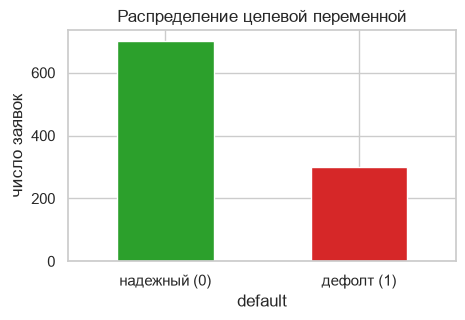

In [5]:
rate = df['default'].mean()
print(f'Доля дефолтов: {rate:.1%} ({df.default.sum()} из {len(df)})')
ax = df['default'].map({0: 'надежный (0)', 1: 'дефолт (1)'}).value_counts().plot.bar(rot=0, color=['tab:green', 'tab:red'], figsize=(5, 3))
ax.set_title('Распределение целевой переменной'); ax.set_ylabel('число заявок');

Классы несбалансированы (70/30), поэтому accuracy — плохая основная метрика: модель «всем одобрить» уже дает 70 %. Основная метрика — **ROC-AUC**, она не зависит от порога и баланса классов.

### Разведочный анализ: числовые признаки по классам

default,надежные,дефолт
duration,19.207,24.860
credit_amount,2985.457,3938.127
installment_commitment,2.920,3.097
residence_since,2.843,2.850
age,36.224,33.963
existing_credits,1.424,1.367
num_dependents,1.156,1.153


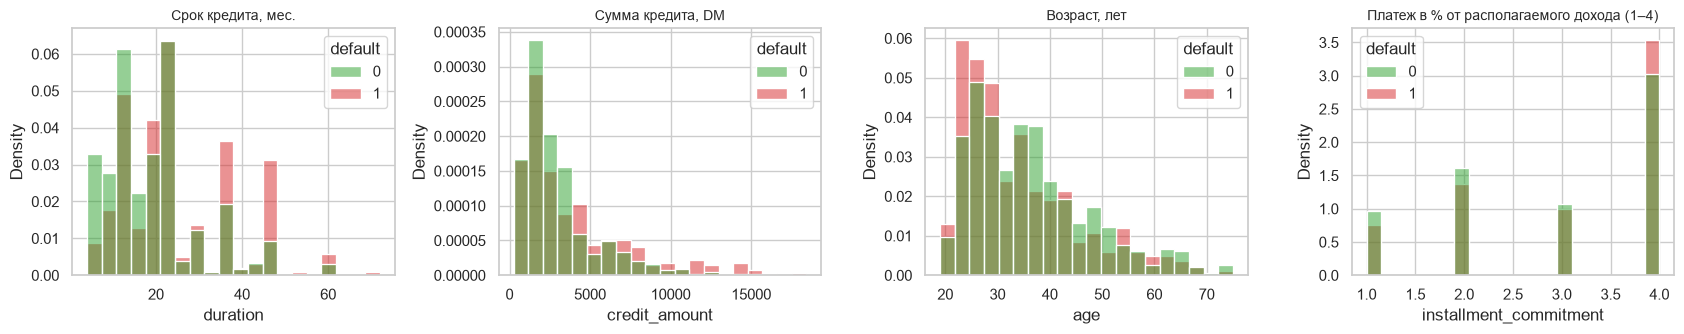

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.5))
for ax, c in zip(axes, ['duration', 'credit_amount', 'age', 'installment_commitment']):
    sns.histplot(df, x=c, hue='default', stat='density', common_norm=False, bins=20,
                 palette={0: 'tab:green', 1: 'tab:red'}, ax=ax)
    ax.set_title(DESCR[c], fontsize=10)
plt.tight_layout()
df.groupby('default')[NUM].mean().T.rename(columns={0: 'надежные', 1: 'дефолт'})

### Доля дефолтов по категориям

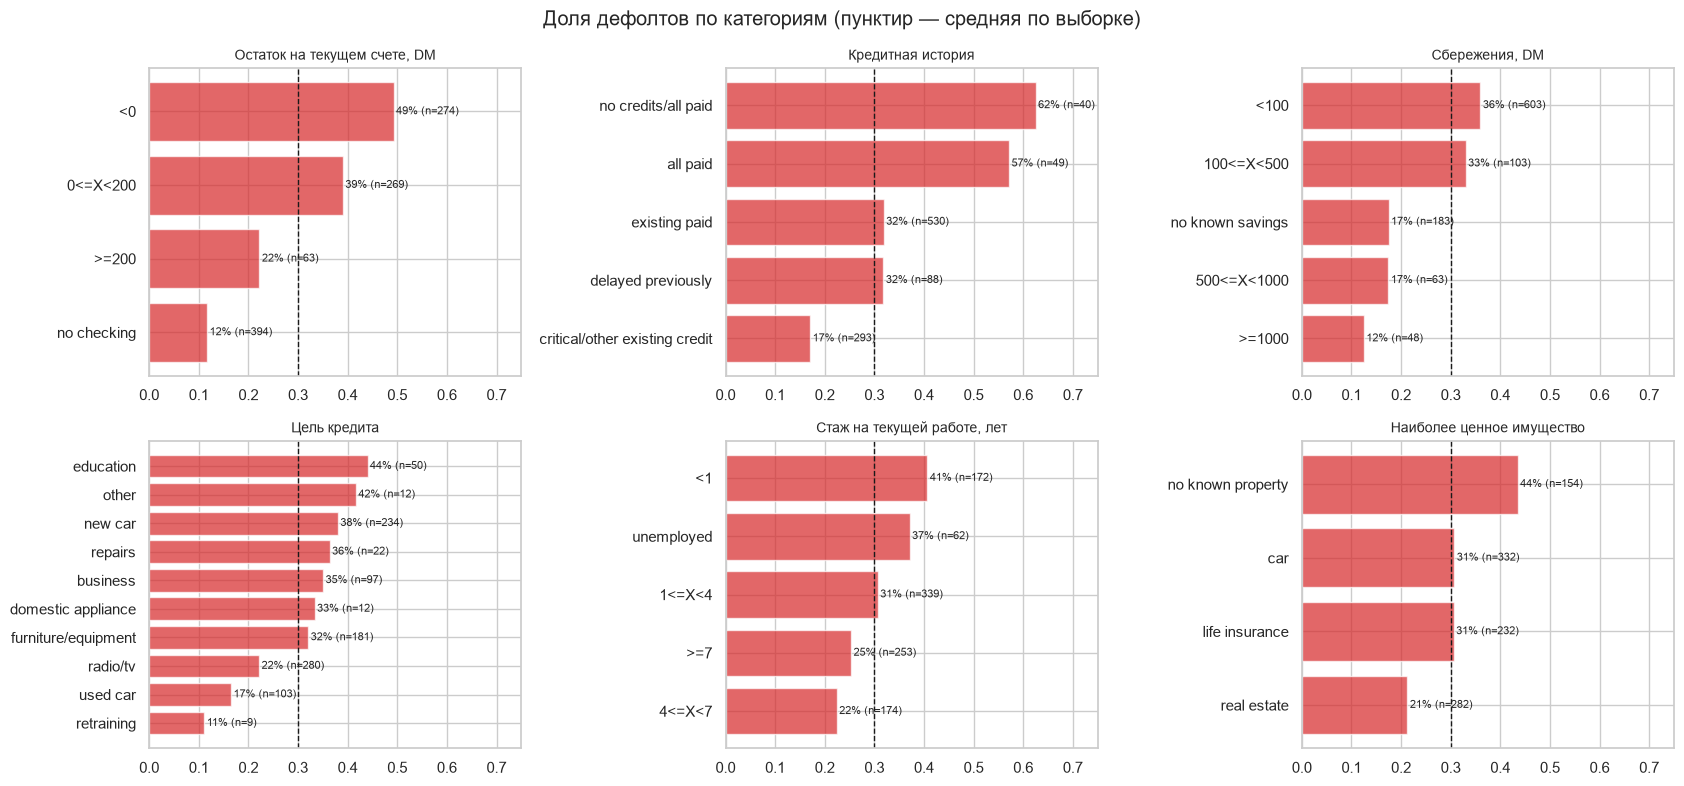

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, c in zip(axes.flat, ['checking_status', 'credit_history', 'savings_status',
                             'purpose', 'employment', 'property_magnitude']):
    g = df.groupby(c)['default'].agg(['mean', 'size']).sort_values('mean')
    ax.barh(g.index, g['mean'], color='tab:red', alpha=.7)
    ax.axvline(rate, color='k', ls='--', lw=1)
    for i, (m, n) in enumerate(zip(g['mean'], g['size'])):
        ax.text(m + .005, i, f'{m:.0%} (n={n})', va='center', fontsize=8)
    ax.set_title(DESCR[c], fontsize=10); ax.set_xlim(0, .75)
plt.suptitle('Доля дефолтов по категориям (пунктир — средняя по выборке)'); plt.tight_layout()

### Корреляции числовых признаков

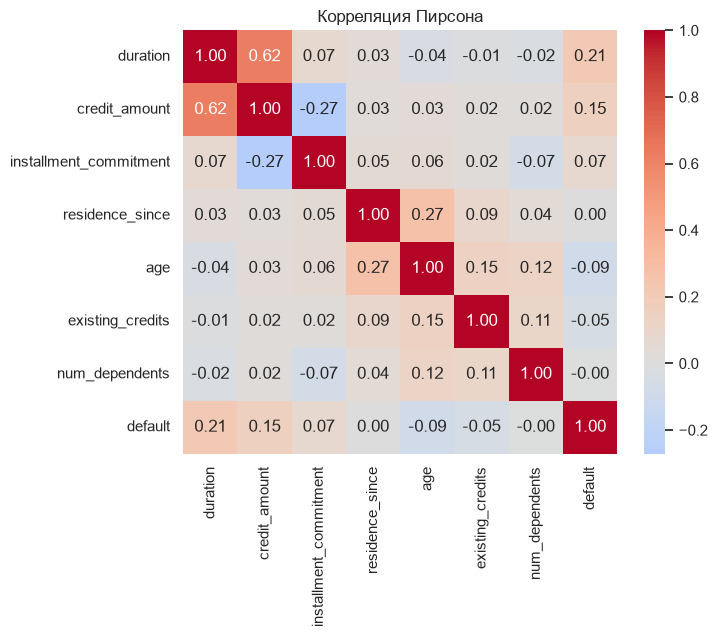

In [8]:
plt.figure(figsize=(7, 5.5))
sns.heatmap(df[NUM + ['default']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Корреляция Пирсона');

## 2. Предобработка данных

- **Пропуски** — отсутствуют (проверено выше), импутация не нужна.
- **Дубликаты** — проверяем ниже.
- **Новый признак** `monthly_amount = credit_amount / duration` — средняя сумма погашения в месяц (нагрузка на заемщика).
- **Исключаем защищенные признаки** `personal_status` (содержит пол) и `foreign_worker` (происхождение): использование таких признаков в скоринге — дискриминация, запрещенная регуляторами (ECOA в США, GDPR/AI Act в ЕС, ст. 5 Закона «О потребительском кредите» в РФ ориентирует банки на финансовые признаки).
- **Кодирование**: категориальные — One-Hot, числовые — стандартизация (важно для логистической регрессии; деревьям не мешает).
- **Разбиение**: train 75 % / test 25 % со стратификацией по целевой переменной; все оценки признаков и подбор модели — только на train.

In [9]:
print('Дубликатов строк:', df.duplicated().sum())
print('Пропусков всего:', df.isna().sum().sum())

df['monthly_amount'] = df['credit_amount'] / df['duration']
DESCR['monthly_amount'] = 'Сумма кредита / срок, DM в мес.'
PROTECTED = ['personal_status', 'foreign_worker']
NUM = NUM + ['monthly_amount']
CAT = [c for c in CAT if c not in PROTECTED]
FEATURES = NUM + CAT

X, y = df[FEATURES], df['default']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
print(f'train: {X_train.shape}, доля дефолтов {y_train.mean():.1%}')
print(f'test:  {X_test.shape}, доля дефолтов {y_test.mean():.1%}')

Дубликатов строк: 0
Пропусков всего: 0
train: (750, 19), доля дефолтов 30.0%
test:  (250, 19), доля дефолтов 30.0%


## 3. Выявление главных признаков

В кредитном скоринге стандартный инструмент отбора признаков — **Information Value (IV)** на основе Weight of Evidence:

$$WoE_i = \ln\frac{\%\,надежных_i}{\%\,дефолтных_i}, \qquad IV = \sum_i (\%\,надежных_i - \%\,дефолтных_i)\cdot WoE_i$$

Числовые признаки предварительно разбиваются на 5 квантильных интервалов. Шкала: IV < 0,02 — бесполезный, 0,02–0,1 — слабый, 0,1–0,3 — средний, > 0,3 — сильный. Считается только на train.

,описание,IV,сила
checking_status,"Остаток на текущем счете, DM",0.628,сильный
credit_history,Кредитная история,0.262,средний
savings_status,"Сбережения, DM",0.232,средний
duration,"Срок кредита, мес.",0.192,средний
property_magnitude,Наиболее ценное имущество,0.151,средний
purpose,Цель кредита,0.147,средний
employment,"Стаж на текущей работе, лет",0.128,средний
other_payment_plans,Другие рассрочки,0.093,слабый
housing,Жилье,0.091,слабый
credit_amount,"Сумма кредита, DM",0.071,слабый


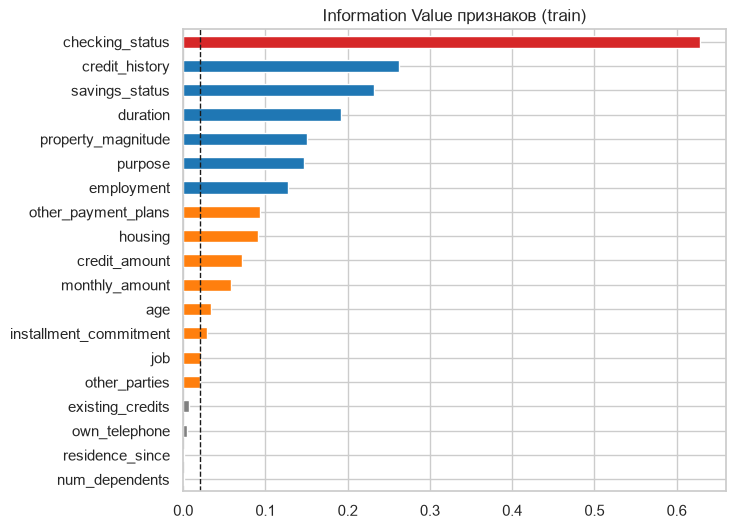

In [10]:
def information_value(x, y, bins=5):
    if x.dtype.kind in 'if' and x.nunique() > 10:
        x = pd.qcut(x, bins, duplicates='drop')
    t = pd.crosstab(x, y)
    good = (t[0] + 0.5) / t[0].sum()   # +0.5 — сглаживание пустых ячеек
    bad = (t[1] + 0.5) / t[1].sum()
    return float(((good - bad) * np.log(good / bad)).sum())

iv = pd.Series({c: information_value(X_train[c], y_train) for c in FEATURES}).sort_values(ascending=False)
strength = pd.cut(iv, [-1, .02, .1, .3, 99], labels=['бесполезный', 'слабый', 'средний', 'сильный'])
iv_tbl = pd.DataFrame({'описание': [DESCR[c] for c in iv.index], 'IV': iv, 'сила': strength})
display(iv_tbl)

ax = iv.sort_values().plot.barh(figsize=(7, 6), color=strength.sort_index().reindex(iv.sort_values().index)
                                .map({'бесполезный': 'grey', 'слабый': 'tab:orange', 'средний': 'tab:blue', 'сильный': 'tab:red'}))
ax.axvline(.02, color='k', ls='--', lw=1); ax.set_title('Information Value признаков (train)');

In [11]:
SELECTED = iv[iv >= 0.02].index.tolist()
print(f'Отобрано {len(SELECTED)} из {len(FEATURES)} признаков (IV ≥ 0.02):')
print(SELECTED)
print('Отброшены:', [c for c in FEATURES if c not in SELECTED])

Отобрано 15 из 19 признаков (IV ≥ 0.02):
['checking_status', 'credit_history', 'savings_status', 'duration', 'property_magnitude', 'purpose', 'employment', 'other_payment_plans', 'housing', 'credit_amount', 'monthly_amount', 'age', 'installment_commitment', 'job', 'other_parties']
Отброшены: ['residence_since', 'existing_credits', 'num_dependents', 'own_telephone']


## 4. Выбор модели

Сравниваем на 5-fold стратифицированной кросс-валидации (только train) четыре модели на всех признаках и на отобранных:
- **логистическая регрессия** — классика скоринга, интерпретируемая, дает хорошо откалиброванные вероятности;
- **случайный лес**;
- **градиентный бустинг**;
- **ансамбль** — мягкое голосование (усреднение вероятностей) трех моделей.

Веса классов не меняем, чтобы `predict_proba` оставалась оценкой реальной вероятности дефолта (PD) — она нужна для экономического расчета.

In [12]:
def make_prep(cols):
    return ColumnTransformer([
        ('num', StandardScaler(), [c for c in cols if c in NUM]),
        ('cat', OneHotEncoder(handle_unknown='ignore'), [c for c in cols if c in CAT]),
    ])

def make_models():
    lr = LogisticRegression(C=0.3, max_iter=2000)
    rf = RandomForestClassifier(n_estimators=500, min_samples_leaf=5, n_jobs=-1, random_state=SEED)
    gb = GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=SEED)
    return {
        'Логистическая регрессия': lr,
        'Случайный лес': rf,
        'Градиентный бустинг': gb,
        'Ансамбль (soft voting)': VotingClassifier([('lr', lr), ('rf', rf), ('gb', gb)], voting='soft'),
    }

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows = []
for feats_name, feats in [('все признаки', FEATURES), ('отобранные (IV)', SELECTED)]:
    for name, model in make_models().items():
        s = cross_validate(make_pipeline(make_prep(feats), model), X_train[feats], y_train, cv=cv,
                           scoring=['roc_auc', 'neg_brier_score'])
        rows.append({'модель': name, 'признаки': feats_name, 'ROC-AUC (CV)': s['test_roc_auc'].mean(),
                     'std': s['test_roc_auc'].std(), 'Brier (CV)': -s['test_neg_brier_score'].mean()})
cv_res = pd.DataFrame(rows).pivot(index='модель', columns='признаки', values=['ROC-AUC (CV)', 'std', 'Brier (CV)'])
cv_res

ROC-AUC (CV)                          std  \
признаки                все признаки отобранные (IV) все признаки   
модель                                                              
Ансамбль (soft voting)         0.783           0.787        0.020   
Градиентный бустинг            0.766           0.775        0.017   
Логистическая регрессия        0.765           0.771        0.021   
Случайный лес                  0.793           0.791        0.016   

                                          Brier (CV)                  
признаки                отобранные (IV) все признаки отобранные (IV)  
модель                                                                
Ансамбль (soft voting)            0.017        0.165           0.164  
Градиентный бустинг               0.017        0.174           0.171  
Логистическая регрессия           0.016        0.172           0.170  
Случайный лес                     0.014        0.167           0.167

Отбор признаков по IV почти не меняет качество (разница в пределах разброса фолдов), но упрощает модель — дальше используем отобранные признаки.

**Правило выбора модели:** различия ROC-AUC между моделями сопоставимы со стандартным отклонением по фолдам, поэтому среди моделей, у которых CV ROC-AUC не ниже «лучший − 1 std», выбираем ту, у которой меньше Brier score — то есть с более точными вероятностями. Точность PD важна, так как на ней строятся пороги решения и расчет EV.

In [13]:
sel = cv_res.xs('отобранные (IV)', axis=1, level=1)
best_auc = sel['ROC-AUC (CV)'].max()
cand = sel[sel['ROC-AUC (CV)'] >= best_auc - sel.loc[sel['ROC-AUC (CV)'].idxmax(), 'std']]
BEST = cand['Brier (CV)'].idxmin()
print('Кандидаты (в пределах 1 std от лучшего ROC-AUC):', list(cand.index))
print(f'Выбрана модель: {BEST} (CV ROC-AUC {sel.loc[BEST, "ROC-AUC (CV)"]:.3f}, Brier {sel.loc[BEST, "Brier (CV)"]:.3f})')

# обучаем все модели на train (для сравнения на test), финальная — BEST
fitted = {name: make_pipeline(make_prep(SELECTED), m).fit(X_train[SELECTED], y_train)
          for name, m in make_models().items()}
final = fitted[BEST]
pd_test = final.predict_proba(X_test[SELECTED])[:, 1]   # PD — вероятность дефолта

Кандидаты (в пределах 1 std от лучшего ROC-AUC): ['Ансамбль (soft voting)', 'Случайный лес']
Выбрана модель: Ансамбль (soft voting) (CV ROC-AUC 0.787, Brier 0.164)


## 5. Метрики качества на отложенной выборке

- **ROC-AUC** — вероятность того, что случайный дефолтный заемщик получит PD выше случайного надежного;
- **Gini = 2·ROC-AUC − 1** — принятая в банках форма той же метрики;
- **доля выявленных дефолтных заемщиков** = TP / (TP + FN) (recall / TPR);
- **доля ошибочно отклоненных надежных** = FP / (FP + TN) (FPR);
- precision, F1, accuracy, Brier score (точность вероятностей, меньше — лучше).

Пороговые метрики приведены для порога отказа PD ≥ 0,5.

In [14]:
def metrics(y_true, pd_, thr=0.5):
    pred = (pd_ >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    auc = roc_auc_score(y_true, pd_)
    return {
        'ROC-AUC': auc, 'Gini': 2 * auc - 1,
        'выявлено дефолтных (TPR)': tp / (tp + fn),
        'ошибочно отклонено надежных (FPR)': fp / (fp + tn),
        'precision': precision_score(y_true, pred), 'F1': f1_score(y_true, pred),
        'accuracy': accuracy_score(y_true, pred), 'Brier': brier_score_loss(y_true, pd_),
    }

test_res = pd.DataFrame({n: metrics(y_test, m.predict_proba(X_test[SELECTED])[:, 1]) for n, m in fitted.items()}).T
test_res

,ROC-AUC,Gini,выявлено дефолтных (TPR),ошибочно отклонено надежных (FPR),precision,F1,accuracy,Brier
Логистическая регрессия,0.800,0.600,0.507,0.103,0.679,0.580,0.780,0.158
Случайный лес,0.797,0.595,0.347,0.080,0.650,0.452,0.748,0.163
Градиентный бустинг,0.809,0.618,0.547,0.091,0.719,0.621,0.800,0.153
Ансамбль (soft voting),0.813,0.625,0.467,0.091,0.686,0.556,0.776,0.153


Ансамбль (soft voting): ROC-AUC = 0.813, Gini = 0.625


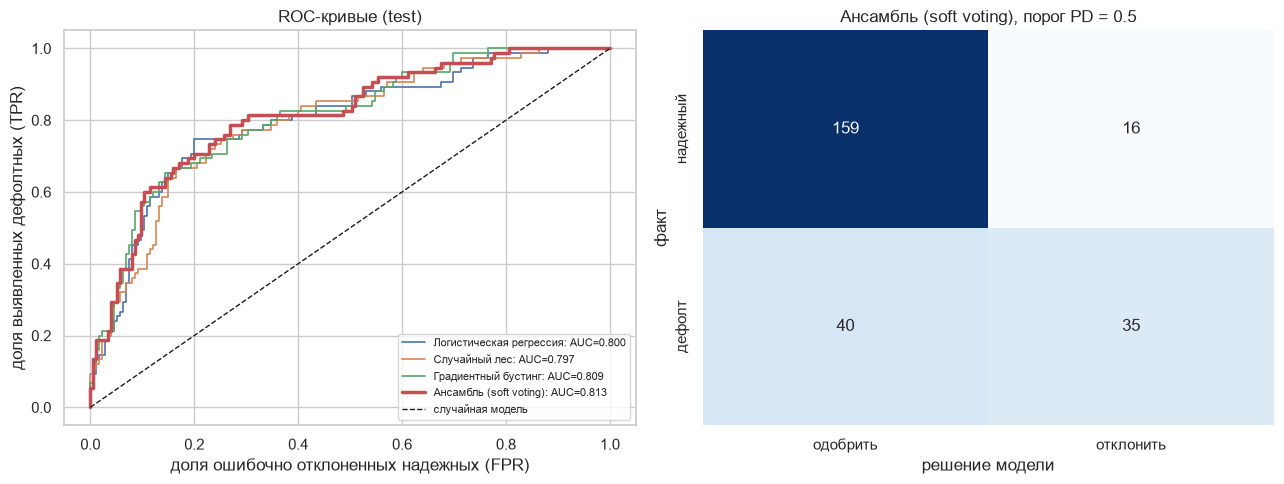

In [15]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5))
for n, m in fitted.items():
    p = m.predict_proba(X_test[SELECTED])[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    a1.plot(fpr, tpr, lw=2.5 if n == BEST else 1.2, label=f'{n}: AUC={roc_auc_score(y_test, p):.3f}')
a1.plot([0, 1], [0, 1], 'k--', lw=1, label='случайная модель')
a1.set_xlabel('доля ошибочно отклоненных надежных (FPR)'); a1.set_ylabel('доля выявленных дефолтных (TPR)')
a1.set_title('ROC-кривые (test)'); a1.legend(fontsize=8)

cm = confusion_matrix(y_test, (pd_test >= .5).astype(int))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=a2, cbar=False,
            xticklabels=['одобрить', 'отклонить'], yticklabels=['надежный', 'дефолт'])
a2.set_xlabel('решение модели'); a2.set_ylabel('факт'); a2.set_title(f'{BEST}, порог PD = 0.5')
plt.tight_layout()

m = metrics(y_test, pd_test)
print(f"{BEST}: ROC-AUC = {m['ROC-AUC']:.3f}, Gini = {m['Gini']:.3f}")

### Компромисс порога: доля выявленных дефолтов vs. ошибочные отказы

In [16]:
thr_tbl = pd.DataFrame({t: metrics(y_test, pd_test, t) for t in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]}).T
thr_tbl.index.name = 'порог отказа PD ≥'
thr_tbl.drop(columns=['ROC-AUC', 'Gini', 'Brier'])

,выявлено дефолтных (TPR),ошибочно отклонено надежных (FPR),precision,F1,accuracy
порог отказа PD ≥,,,,,
0.100,0.960,0.749,0.355,0.518,0.464
0.200,0.813,0.474,0.424,0.557,0.612
0.300,0.760,0.263,0.553,0.640,0.744
0.400,0.640,0.149,0.649,0.644,0.788
0.500,0.467,0.091,0.686,0.556,0.776
0.600,0.360,0.057,0.730,0.482,0.768


## 6. Правило принятия решения по заявкам

Трехзонное правило по предсказанной вероятности дефолта (PD):

| PD | Решение |
|---|---|
| < 0,20 | **одобрить** автоматически |
| 0,20 – 0,50 | **дополнительная проверка** (андеррайтер, запрос документов, залог/поручитель) |
| ≥ 0,50 | **отклонить** |

,заявок,средний_PD,факт_доля_дефолтов,дефолтов,доля_заявок
zone,,,,,
одобрить,106,0.111,0.132,14,0.424
доп. проверка,93,0.326,0.280,26,0.372
отклонить,51,0.639,0.686,35,0.204


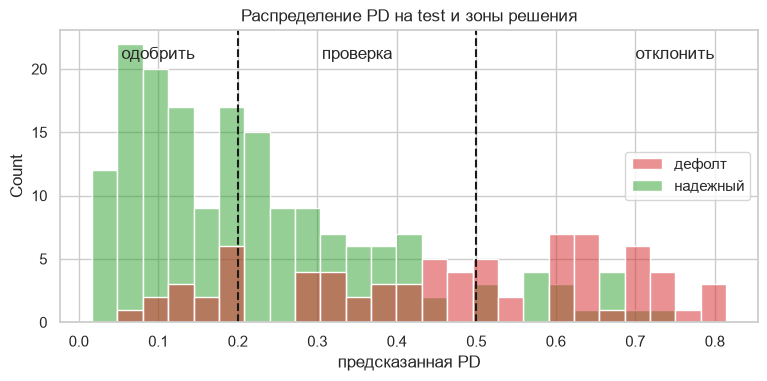

In [17]:
LOW, HIGH = 0.20, 0.50
ZONES = ['одобрить', 'доп. проверка', 'отклонить']

def zone(pd_):
    return pd.cut(pd_, [-0.01, LOW, HIGH, 1.01], right=False, labels=ZONES)

z = zone(pd_test)
zone_tbl = pd.DataFrame({'zone': z, 'pd': pd_test, 'y': y_test.values}).groupby('zone', observed=False).agg(
    заявок=('y', 'size'), средний_PD=('pd', 'mean'), факт_доля_дефолтов=('y', 'mean'), дефолтов=('y', 'sum'))
zone_tbl['доля_заявок'] = zone_tbl['заявок'] / len(z)
display(zone_tbl)

plt.figure(figsize=(9, 3.8))
sns.histplot(x=pd_test, hue=y_test.map({0: 'надежный', 1: 'дефолт'}).values, bins=25, stat='count',
             palette={'надежный': 'tab:green', 'дефолт': 'tab:red'})
for t in (LOW, HIGH): plt.axvline(t, color='k', ls='--')
plt.text(LOW / 2, plt.ylim()[1] * .9, 'одобрить', ha='center')
plt.text((LOW + HIGH) / 2, plt.ylim()[1] * .9, 'проверка', ha='center')
plt.text((HIGH + 1) / 2, plt.ylim()[1] * .9, 'отклонить', ha='center')
plt.xlabel('предсказанная PD'); plt.title('Распределение PD на test и зоны решения');

## 7. Экономический эффект

Ожидаемая ценность кредита: $EV = (1 - PD)\cdot R - PD\cdot L$.

Допущения (датасет не содержит ставок, поэтому параметры заданы явно и ниже проверяется чувствительность к ним):
- **R** — процентный доход банка: `credit_amount × ставка × срок/12`, ставка **15 % годовых** (простые проценты);
- **L** — потери при дефолте: `credit_amount × LGD`, **LGD = 60 %** (типичный уровень для необеспеченных потребкредитов);
- **ручная проверка** стоит **100 DM** за заявку; андеррайтер отклоняет **70 %** дефолтных и по ошибке **15 %** надежных заявок из зоны проверки.

Сценарии оценки заемщиков (считаем фактическую прибыль на test по реальным исходам: одобренный надежный приносит +R, одобренный дефолтный — −L):
1. **Без модели** — одобрить всех;
2. **Модель, порог 0,5** — одобрить, если PD < 0,5;
3. **Трехзонное правило** 0,20 / 0,50 с ручной проверкой;
4. **EV-правило** — одобрить, если EV > 0, т.е. PD < R / (R + L) (индивидуальный порог для каждой заявки);
5. **Идеальная модель** — одобрить ровно всех надежных (верхняя граница).

,"одобрено, %","дефолтов среди одобренных, %",упущено надежных,"ожидаемый EV по модели, DM","фактическая прибыль, DM","прибыль на заявку, DM"
1. Без модели (одобрить всех),100.0,30.0,0.0,"-4,823.4","-33,032.4",-132.1
"2. Модель, порог 0.5",79.6,20.1,16.0,"56,651.8","45,378.3",181.5
3. Трехзонное 0.2/0.5 + проверка,68.3,12.8,26.0,"45,585.5","73,994.6",296.0
4. EV-правило (EV > 0),51.2,17.2,69.0,"69,998.3","55,636.0",222.5
5. Идеальная модель,70.0,0.0,0.0,"35,386.4","167,773.2",671.1


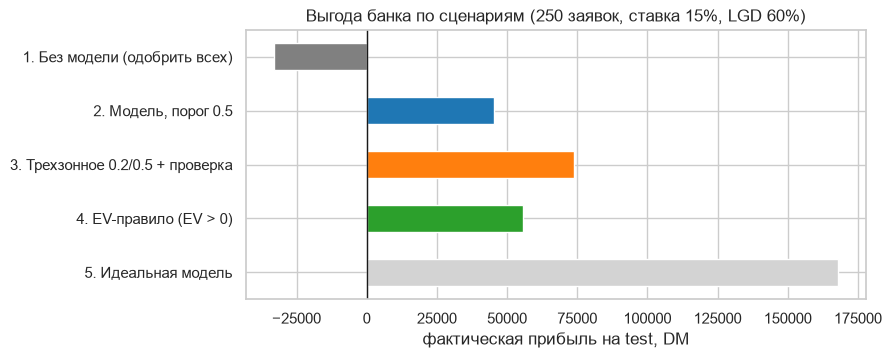

In [18]:
RATE, LGD = 0.15, 0.60
REVIEW_COST, CATCH_BAD, REJECT_GOOD = 100, 0.70, 0.15

amt, dur = X_test['credit_amount'].values, X_test['duration'].values
yt = y_test.values

def scenarios(pd_, rate=RATE, lgd=LGD):
    R = amt * rate * dur / 12
    L = amt * lgd
    ev = (1 - pd_) * R - pd_ * L
    # доля одобрения для каждой заявки (для зоны проверки — вероятность одобрения андеррайтером)
    review = (pd_ >= LOW) & (pd_ < HIGH)
    three = np.where(pd_ < LOW, 1.0, 0.0) + review * np.where(yt == 1, 1 - CATCH_BAD, 1 - REJECT_GOOD)
    plans = {
        '1. Без модели (одобрить всех)': (np.ones_like(pd_), 0),
        '2. Модель, порог 0.5': ((pd_ < 0.5).astype(float), 0),
        '3. Трехзонное 0.2/0.5 + проверка': (three, review.sum() * REVIEW_COST),
        '4. EV-правило (EV > 0)': ((ev > 0).astype(float), 0),
        '5. Идеальная модель': ((yt == 0).astype(float), 0),
    }
    rows = {}
    for name, (appr, cost) in plans.items():
        profit = np.sum(appr * np.where(yt == 0, R, -L)) - cost
        rows[name] = {
            'одобрено, %': appr.mean() * 100,
            'дефолтов среди одобренных, %': 100 * np.sum(appr * yt) / max(appr.sum(), 1e-9),
            'упущено надежных': np.sum((1 - appr) * (yt == 0)),
            'ожидаемый EV по модели, DM': np.sum(appr * ev) - cost,
            'фактическая прибыль, DM': profit,
        }
    return pd.DataFrame(rows).T

econ = scenarios(pd_test)
econ['прибыль на заявку, DM'] = econ['фактическая прибыль, DM'] / len(yt)
display(econ.style.format('{:,.1f}'))

ax = econ['фактическая прибыль, DM'].plot.barh(figsize=(8, 3.5), color=['grey', 'tab:blue', 'tab:orange', 'tab:green', 'lightgrey'])
ax.axvline(0, color='k', lw=1); ax.invert_yaxis(); ax.set_xlabel('фактическая прибыль на test, DM')
ax.set_title(f'Выгода банка по сценариям ({len(yt)} заявок, ставка {RATE:.0%}, LGD {LGD:.0%})');

### Прибыль в зависимости от единого порога отказа

Оптимальный единый порог на test: PD < 0.32; медианный порог безубыточности R/(R+L) = 0.27


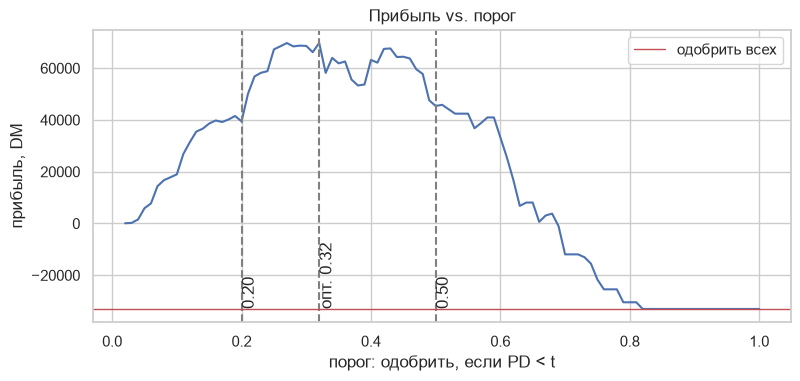

In [19]:
R_, L_ = amt * RATE * dur / 12, amt * LGD
grid = np.linspace(0.02, 1.0, 99)
profit_curve = [np.sum((pd_test < t) * np.where(yt == 0, R_, -L_)) for t in grid]
t_opt = grid[int(np.argmax(profit_curve))]
be = np.median(R_ / (R_ + L_))
print(f'Оптимальный единый порог на test: PD < {t_opt:.2f}; медианный порог безубыточности R/(R+L) = {be:.2f}')

plt.figure(figsize=(9, 3.8))
plt.plot(grid, profit_curve)
for t, lbl in [(LOW, '0.20'), (HIGH, '0.50'), (t_opt, f'опт. {t_opt:.2f}')]:
    plt.axvline(t, ls='--', color='grey'); plt.text(t, min(profit_curve), lbl, rotation=90, va='bottom')
plt.axhline(profit_curve[-1], color='r', lw=1, label='одобрить всех')
plt.xlabel('порог: одобрить, если PD < t'); plt.ylabel('прибыль, DM'); plt.legend(); plt.title('Прибыль vs. порог');

### Чувствительность к ставке и LGD

In [20]:
sens = []
for rate in [0.10, 0.15, 0.20]:
    for lgd in [0.45, 0.60, 0.75]:
        e = scenarios(pd_test, rate, lgd)['фактическая прибыль, DM']
        sens.append({'ставка': f'{rate:.0%}', 'LGD': f'{lgd:.0%}', **e.drop('5. Идеальная модель').round(0).to_dict(),
                     'лучший сценарий': e.drop('5. Идеальная модель').idxmax()})
pd.DataFrame(sens).set_index(['ставка', 'LGD'])

1. Без модели (одобрить всех)  2. Модель, порог 0.5  \
ставка LGD                                                        
10%    45%                     -38755.000             22383.000   
       60%                     -88957.000             -1224.000   
       75%                    -139158.000            -24832.000   
15%    45%                      17169.000             68986.000   
       60%                     -33032.000             45378.000   
       75%                     -83234.000             21771.000   
20%    45%                      73093.000            115588.000   
       60%                      22892.000             91981.000   
       75%                     -27309.000             68374.000   

            3. Трехзонное 0.2/0.5 + проверка  4. EV-правило (EV > 0)  \
ставка LGD                                                             
10%    45%                         42476.000               39137.000   
       60%                         31216.000               39165.000   
       75%                         19955.000               40534.000   
15%    45%                         85255.000               74984.000   
       60%                         73995.000               55636.000   
       75%                         62734.000               50838.000   
20%    45%                        128034.000              113568.000   
       60%                        116773.000               99978.000   
       75%                        105513.000               81199.000   

                             лучший сценарий  
ставка LGD                                    
10%    45%  3. Трехзонное 0.2/0.5 + проверка  
       60%            4. EV-правило (EV > 0)  
       75%            4. EV-правило (EV > 0)  
15%    45%  3. Трехзонное 0.2/0.5 + проверка  
       60%  3. Трехзонное 0.2/0.5 + проверка  
       75%  3. Трехзонное 0.2/0.5 + проверка  
20%    45%  3. Трехзонное 0.2/0.5 + проверка  
       60%  3. Трехзонное 0.2/0.5 + проверка  
       75%  3. Трехзонное 0.2/0.5 + проверка

## 8. Профиль рискованного заемщика

1. **Значимость признаков** для финальной модели — permutation importance на test (насколько падает ROC-AUC при перемешивании признака).
2. **Направление влияния** — коэффициенты логистической регрессии (отношения шансов).
3. **Сравнение групп** заемщиков из зоны «отклонить» и зоны «одобрить».

checking_status           0.101
credit_amount             0.028
purpose                   0.015
duration                  0.013
credit_history            0.012
monthly_amount            0.008
other_parties             0.008
age                       0.007
savings_status            0.006
other_payment_plans       0.004
housing                   0.002
employment                0.002
job                       0.001
installment_commitment   -0.001
property_magnitude       -0.001
dtype: float64

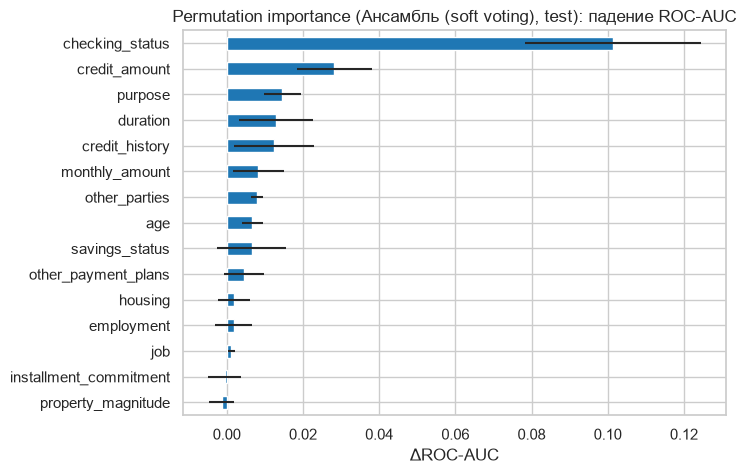

In [21]:
pi = permutation_importance(final, X_test[SELECTED], y_test, scoring='roc_auc', n_repeats=30, random_state=SEED)
imp = pd.Series(pi.importances_mean, SELECTED).sort_values()
ax = imp.plot.barh(figsize=(7, 5), xerr=pd.Series(pi.importances_std, SELECTED)[imp.index], color='tab:blue')
ax.set_title(f'Permutation importance ({BEST}, test): падение ROC-AUC'); ax.set_xlabel('ΔROC-AUC')
imp.sort_values(ascending=False).round(4)

,коэф.,отношение шансов
cat__purpose_education,0.735,2.086
cat__savings_status_<100,0.616,1.851
cat__checking_status_<0,0.609,1.839
cat__property_magnitude_no known property,0.438,1.550
cat__credit_history_no credits/all paid,0.438,1.549
cat__housing_rent,0.408,1.504
cat__employment_unemployed,0.357,1.429
cat__purpose_new car,0.340,1.404
cat__other_parties_guarantor,-0.317,0.728
cat__other_payment_plans_none,-0.337,0.714


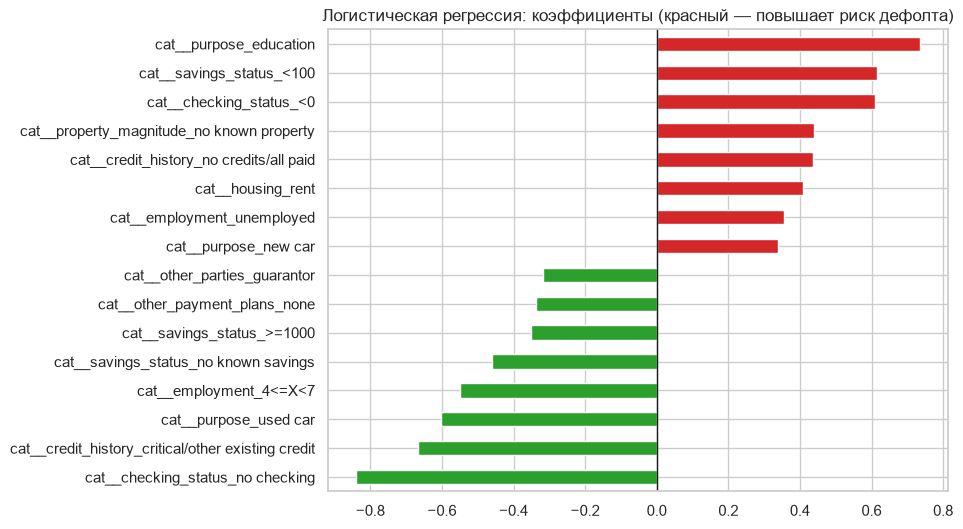

In [22]:
lr = fitted['Логистическая регрессия']
names = lr[0].get_feature_names_out()
coef = pd.Series(lr[-1].coef_[0], names).sort_values()
odds = np.exp(coef)
top = pd.concat([coef.head(8), coef.tail(8)])
ax = top.plot.barh(figsize=(8, 6), color=np.where(top > 0, 'tab:red', 'tab:green'))
ax.set_title('Логистическая регрессия: коэффициенты (красный — повышает риск дефолта)'); ax.axvline(0, color='k', lw=1);
pd.DataFrame({'коэф.': top, 'отношение шансов': np.exp(top)}).iloc[::-1]

In [23]:
test_df = X_test.assign(PD=pd_test, zone=zone(pd_test), default=y_test.values)
hi, lo = test_df[test_df.zone == 'отклонить'], test_df[test_df.zone == 'одобрить']
print(f'Зона «отклонить»: {len(hi)} заявок, факт. доля дефолтов {hi.default.mean():.0%}; '
      f'зона «одобрить»: {len(lo)} заявок, {lo.default.mean():.0%}')
display(pd.DataFrame({'отклонить': hi[NUM].median(), 'одобрить': lo[NUM].median()}).rename(index=DESCR)
        .style.set_caption('Медианы числовых признаков').format('{:.1f}'))

# для каждого признака — категория, сильнее всего перепредставленная в зоне «отклонить»
prof = []
for c in [c for c in SELECTED if c in CAT]:
    diff = hi[c].value_counts(normalize=True).sub(lo[c].value_counts(normalize=True), fill_value=0)
    cat = diff.idxmax()
    prof.append({'признак': DESCR[c], 'характерная категория': cat,
                 'доля в «отклонить»': (hi[c] == cat).mean(), 'доля в «одобрить»': (lo[c] == cat).mean(),
                 'доля дефолтов в категории (вся выборка)': df.loc[df[c] == cat, 'default'].mean()})
(pd.DataFrame(prof).sort_values('доля дефолтов в категории (вся выборка)', ascending=False)
 .style.format({k: '{:.0%}' for k in ['доля в «отклонить»', 'доля в «одобрить»', 'доля дефолтов в категории (вся выборка)']}))

Зона «отклонить»: 51 заявок, факт. доля дефолтов 69%; зона «одобрить»: 106 заявок, 13%


,отклонить,одобрить
"Срок кредита, мес.",24.0,12.0
"Сумма кредита, DM",3234.0,1996.0
Платеж в % от располагаемого дохода (1–4),4.0,3.0
Лет по текущему адресу,4.0,2.0
"Возраст, лет",29.0,36.0
Число кредитов в этом банке,1.0,1.0
Число иждивенцев,1.0,1.0
"Сумма кредита / срок, DM в мес.",124.1,148.9


,признак,характерная категория,доля в «отклонить»,доля в «одобрить»,доля дефолтов в категории (вся выборка)
0,"Остаток на текущем счете, DM",<0,69%,6%,49%
4,Цель кредита,education,12%,3%,44%
3,Наиболее ценное имущество,no known property,25%,6%,44%
6,Другие рассрочки,bank,18%,5%,41%
5,"Стаж на текущей работе, лет",<1,25%,10%,41%
7,Жилье,rent,31%,9%,39%
2,"Сбережения, DM",<100,90%,45%,36%
8,Квалификация,high qualif/self emp/mgmt,24%,12%,34%
1,Кредитная история,existing paid,69%,51%,32%
9,Поручитель / созаемщик,none,94%,91%,30%


## 9. Вывод

**Данные и модель.** Использован открытый датасет German Credit (UCI): 1000 заявок, 20 признаков, 30 % дефолтов. Пропусков и дубликатов нет; защищенные признаки (пол, иностранное происхождение) исключены из модели; добавлен признак `monthly_amount`. По Information Value отобрано 15 из 19 признаков — качество при этом не ухудшилось. Финальная модель — **ансамбль (мягкое голосование логистической регрессии, случайного леса и градиентного бустинга)**: CV ROC-AUC 0,787, на отложенной выборке **ROC-AUC = 0,813, Gini = 0,625** — это уровень, типичный для рабочих скоринговых моделей (Gini 0,5–0,7).

При пороге отказа PD ≥ 0,5 модель **выявляет 46,7 % дефолтных заемщиков** и **ошибочно отклоняет 9,1 % надежных**. Снижение порога до 0,3 повышает долю выявленных дефолтов до 76 % ценой 26 % ошибочных отказов — выбор порога определяется экономикой, а не accuracy.

**Наиболее значимые признаки** (IV на train / падение ROC-AUC при перемешивании на test):
1. остаток на текущем счете — IV 0,63, ΔAUC 0,10 — главный предиктор;
2. кредитная история — IV 0,26;
3. сбережения — IV 0,23;
4. срок кредита — IV 0,19; сумма кредита — ΔAUC 0,03;
5. имущество, цель кредита, стаж работы — IV 0,13–0,15.

**Профиль рискованного заемщика:**
- отрицательный остаток на текущем счете (< 0 DM: 49 % дефолтов против 30 % в среднем; таких 69 % в зоне «отклонить» и 6 % в зоне «одобрить»);
- сбережения < 100 DM (90 % зоны «отклонить»);
- длинный срок и крупная сумма: медиана 24 мес. и 3 234 DM против 12 мес. и 1 996 DM у одобряемых; максимальная платежная нагрузка (4 из 4);
- моложе: медиана 29 лет против 36;
- нет ценного имущества, жилье в аренде, стаж на текущей работе < 1 года, уже есть рассрочки в других банках;
- цель — образование или новый автомобиль; отсутствие кредитной истории.

Риск снижают: длительный стаж (4–7 лет), значительные сбережения (≥ 1000 DM), наличие поручителя, покупка подержанного автомобиля.

**Правило принятия решения.** Трехзонное правило по PD на test:

| Зона | Доля заявок | Факт. доля дефолтов |
|---|---|---|
| PD < 0,20 — одобрить | 42 % | 13 % |
| 0,20–0,50 — доп. проверка | 37 % | 28 % |
| PD ≥ 0,50 — отклонить | 20 % | 69 % |

Зоны хорошо разделяют риск. Если ручная проверка недоступна, рекомендуется единый порог около **PD ≈ 0,3**: оптимум прибыли на test — 0,32, что согласуется с экономическим порогом безубыточности R / (R + L) ≈ 0,27. Стандартный порог 0,5 для кредитования слишком мягкий.

**Выгода банка** (ставка 15 %, LGD 60 %, 250 заявок test):

| Сценарий | Прибыль, DM | На заявку, DM |
|---|---|---|
| Без модели (одобрить всех) | −33 032 | −132 |
| Модель, порог 0,5 | +45 378 | +182 |
| EV-правило (EV > 0) | +55 636 | +223 |
| Трехзонное 0,2/0,5 + проверка | **+73 995** | **+296** |
| Идеальная модель (предел) | +167 773 | +671 |

Одобрять всех без оценки убыточно: дефолты (30 %) съедают процентный доход. Даже простой порог 0,5 превращает убыток в прибыль (+78 тыс. DM на 250 заявках), трехзонное правило с ручной проверкой дает +107 тыс. DM относительно «одобрить всех». Анализ чувствительности: трехзонное правило лучшее в 7 из 9 сочетаний ставки и LGD; при низкой марже (ставка 10 %) и высоких потерях (LGD ≥ 60 %) выгоднее EV-правило с индивидуальным порогом, а порог 0,5 становится убыточным — чем выше отношение L/R, тем строже должен быть порог.

**Ограничения.** Небольшая выборка (test — 250 заявок), исторические данные (Германия, 1990-е), допущения о ставке, LGD и качестве ручной проверки. Для промышленного применения нужны калибровка на актуальных данных банка и мониторинг дрейфа данных и качества модели в эксплуатации.